# A minimal VAE for extreme Irish wind

This notebook trains a **variational autoencoder (VAE)** on 40 years of daily-maximum wind maps over
Ireland (ERA5, 32 × 32 grid, 1985–2024). It then generates new maps by sampling the latent space, and
makes them more extreme by sampling with a wider spread (σ > 1).

**How to use it**
1. On Colab: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Training takes about a minute.
2. Change the numbers in **Section 1 (settings)** and run everything again. That's the main way to experiment.
3. You're encouraged to edit and break any cell. To get a fresh copy, just reopen the notebook from its Colab link.

Data: *Generated using Copernicus Climate Change Service information [2026]* (ERA5 reanalysis).

## 0 · Setup: get the code and data, find the GPU

In [1]:
import copy, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/jfk1327/ai_weather_pres3.git"
DATA_FILE = Path("data") / "era5_ireland_wind_daily_max.nc"

# Look for the data next to this notebook (running locally) or in an earlier clone (Colab re-run)
candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "ai_weather"]
ROOT = next((p for p in candidates if (p / DATA_FILE).exists()), None)
if ROOT is None:                      # first run on Colab: download the repo, which includes the data
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "ai_weather"], check=True)
    ROOT = Path.cwd() / "ai_weather"
DATA_PATH = ROOT / DATA_FILE

try:
    import netCDF4                    # needed by xarray to read .nc files
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "netCDF4"], check=True)
print("data file:", DATA_PATH)

data file: /home/james/project/AI_weather/data/era5_ireland_wind_daily_max.nc


In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found - training will be slower. On Colab: Runtime -> Change runtime type -> T4 GPU")

Using GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1 · Settings: change these and re-run everything

| Setting | What it controls |
|---|---|
| `VARIABLE` | `"gust"` (daily max gust) or `"speed"` (daily max 10 m wind speed) |
| `LATENT_DIM` | how many numbers the encoder squeezes each 1024-pixel map into |
| `BETA` | weight on the KL term: higher → smoother, more "average" latent space; lower → sharper reconstructions |
| `EPOCHS` | passes over the training data |
| `BATCH_SIZE`, `LR` | maps per gradient step, and the Adam learning rate |
| `BASE_CHANNELS` | width of the network (number of filters in the first conv layer) |
| `SIGMAS` | sampling spreads to compare: σ = 1 is "normal", σ > 1 asks for more unusual maps |

In [3]:
VARIABLE = "gust"
LATENT_DIM = 16
BETA = 1.0
EPOCHS = 30
BATCH_SIZE = 128
LR = 1e-3
BASE_CHANNELS = 32
SIGMAS = [0.5, 1.0, 1.3]
SEED = 0

## 2 · Data

Each sample is **one day**: a 32 × 32 map of the strongest wind at each grid cell (cells ≈ 28 km N–S × 16 km E–W).

- **Split by year, not at random.** Neighbouring days look alike, so a random split would let the model
  "see" the validation days during training. Train 1985–2014, validate 2015–2019, test 2020–2024.
- **Normalise** with one mean and one standard deviation, computed **from the training years only**, so the
  network sees numbers around 0 instead of 0–57 m/s. `denormalise` turns model output back into m/s.

In [4]:
torch.manual_seed(SEED)
ds = xr.open_dataset(DATA_PATH)
maps = ds[VARIABLE]                                            # dims: (time, latitude, longitude)

def years(first, last):
    """All maps from `first` to `last` (inclusive) as a float32 tensor of shape (days, 32, 32), in m/s."""
    return torch.from_numpy(maps.sel(time=slice(str(first), str(last))).values).float()

train_raw, val_raw, test_raw = years(1985, 2014), years(2015, 2019), years(2020, 2024)
print("days  train / val / test:", len(train_raw), len(val_raw), len(test_raw))

MEAN, STD = train_raw.mean(), train_raw.std()                  # training years only!
def normalise(x):   return (x - MEAN) / STD
def denormalise(x): return x * STD + MEAN
print(f"normalisation: mean {MEAN:.2f} m/s, std {STD:.2f} m/s")

def make_loader(raw, shuffle):
    x = normalise(raw).unsqueeze(1)                            # (days, 1, 32, 32): Conv2d wants a channel axis
    return DataLoader(TensorDataset(x), batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(train_raw, shuffle=True)            # shuffle so each batch mixes seasons and years
val_loader = make_loader(val_raw, shuffle=False)               # order doesn't matter for an average
print("one batch:", next(iter(train_loader))[0].shape)

days  train / val / test: 10957 1826 1827
normalisation: mean 14.76 m/s, std 5.79 m/s
one batch: torch.Size([128, 1, 32, 32])


## 3 · The model

```
map (1, 32, 32) ─ encoder ─► μ, log σ²  (LATENT_DIM numbers each)
                                │  z = μ + σ · ε,  ε ~ N(0, 1)     ← "reparameterisation trick"
                                ▼
                z (LATENT_DIM) ─ decoder ─► reconstructed map (1, 32, 32)
```
Each `Conv2d(kernel 4, stride 2, padding 1)` halves the map size: 32 → 16 → 8 → 4.
Each `ConvTranspose2d` with the same settings doubles it back: 4 → 8 → 16 → 32.

In [5]:
class VAE(nn.Module):
    def __init__(self, latent_dim, c):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, c, 4, stride=2, padding=1), nn.ReLU(),          # (1, 32, 32)  -> (c, 16, 16)
            nn.Conv2d(c, 2 * c, 4, stride=2, padding=1), nn.ReLU(),      # -> (2c, 8, 8)
            nn.Conv2d(2 * c, 4 * c, 4, stride=2, padding=1), nn.ReLU(),  # -> (4c, 4, 4)
            nn.Flatten(),                                                # -> 4c * 16 numbers
        )
        n = 4 * c * 4 * 4
        self.to_mu = nn.Linear(n, latent_dim)
        self.to_logvar = nn.Linear(n, latent_dim)                        # log of the variance: can be any real number
        self.from_z = nn.Linear(latent_dim, n)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (4 * c, 4, 4)), nn.ReLU(),                   # -> (4c, 4, 4)
            nn.ConvTranspose2d(4 * c, 2 * c, 4, stride=2, padding=1), nn.ReLU(),  # -> (2c, 8, 8)
            nn.ConvTranspose2d(2 * c, c, 4, stride=2, padding=1), nn.ReLU(),      # -> (c, 16, 16)
            nn.ConvTranspose2d(c, 1, 4, stride=2, padding=1),            # -> (1, 32, 32); no activation: data is normalised
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h)

    def decode(self, z):
        return self.decoder(self.from_z(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)          # sample z, but keep gradients flowing
        return self.decode(z), mu, logvar

model = VAE(LATENT_DIM, BASE_CHANNELS).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

# shape check: 2 fake maps in, 2 maps out
x_hat, mu, logvar = model(torch.zeros(2, 1, 32, 32, device=device))
print("output:", tuple(x_hat.shape), "| mu:", tuple(mu.shape))

parameters: 429,409


output: (2, 1, 32, 32) | mu: (2, 16)


## 4 · The loss

**loss = reconstruction + β · KL**

- **Reconstruction**: squared error between the map and its reconstruction, summed over the 1024 pixels.
  (Using squared error is the same as assuming Gaussian noise on each pixel.)
- **KL**: how far each map's code distribution N(μ, σ²) is from N(0, 1). This pulls the codes of all days
  into one bell-shaped cloud, which is what lets us **sample new maps** from N(0, 1) later.

Both are averaged over the maps in a batch.

In [6]:
def vae_loss(x, x_hat, mu, logvar, beta):
    n = x.shape[0]
    recon = F.mse_loss(x_hat, x, reduction="sum") / n
    kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / n   # closed form for two Gaussians
    return recon + beta * kl, recon, kl

## 5 · Training

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(loader, train):
    """One pass over `loader`. Returns the average [total, recon, kl] per map."""
    model.train(train)
    sums, count = torch.zeros(3), 0
    with torch.set_grad_enabled(train):                  # no gradients needed for validation
        for (x,) in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, recon, kl = vae_loss(x, x_hat, mu, logvar, BETA)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            sums += torch.tensor([loss.item(), recon.item(), kl.item()]) * len(x)
            count += len(x)
    return sums / count

history = {"train": [], "val": []}
best_val, best_state = float("inf"), None
print("epoch | train loss (recon + KL) | val loss (recon + KL) | time")
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    tr, va = run_epoch(train_loader, train=True), run_epoch(val_loader, train=False)
    history["train"].append(tr); history["val"].append(va)
    if va[0] < best_val:                                  # keep the model that does best on validation years
        best_val, best_state = va[0].item(), copy.deepcopy(model.state_dict())
    print(f"{epoch:5d} | {tr[0]:7.1f} ({tr[1]:6.1f} + {tr[2]:5.1f}) | "
          f"{va[0]:7.1f} ({va[1]:6.1f} + {va[2]:5.1f}) | {time.time() - start:4.1f}s")

model.load_state_dict(best_state)
model.eval()
print(f"best validation loss: {best_val:.1f}")

epoch | train loss (recon + KL) | val loss (recon + KL) | time


    1 |   383.8 ( 360.4 +  23.4) |   135.4 ( 111.2 +  24.1) |  1.4s


    2 |   106.4 (  82.2 +  24.2) |    92.4 (  66.8 +  25.6) |  0.6s


    3 |    83.7 (  58.6 +  25.0) |    77.2 (  51.9 +  25.3) |  0.6s


    4 |    74.3 (  49.1 +  25.2) |    70.6 (  45.5 +  25.0) |  0.6s


...

   26 |    51.8 (  28.8 +  23.0) |    52.6 (  28.7 +  23.9) |  0.6s


   27 |    51.7 (  28.7 +  23.0) |    53.3 (  30.7 +  22.7) |  0.6s


   28 |    51.6 (  28.6 +  23.0) |    53.4 (  30.3 +  23.1) |  0.6s


   29 |    52.1 (  29.1 +  23.0) |    52.8 (  30.3 +  22.4) |  0.6s


   30 |    51.3 (  28.4 +  22.9) |    53.0 (  30.1 +  22.9) |  0.6s
best validation loss: 52.6


Optional: save the trained model. On Colab, files disappear when the session ends; to keep one, first
mount Google Drive (`from google.colab import drive; drive.mount("/content/drive")`) and save there.

In [8]:
torch.save(model.state_dict(), "vae.pt")

## 6 · Loss curves

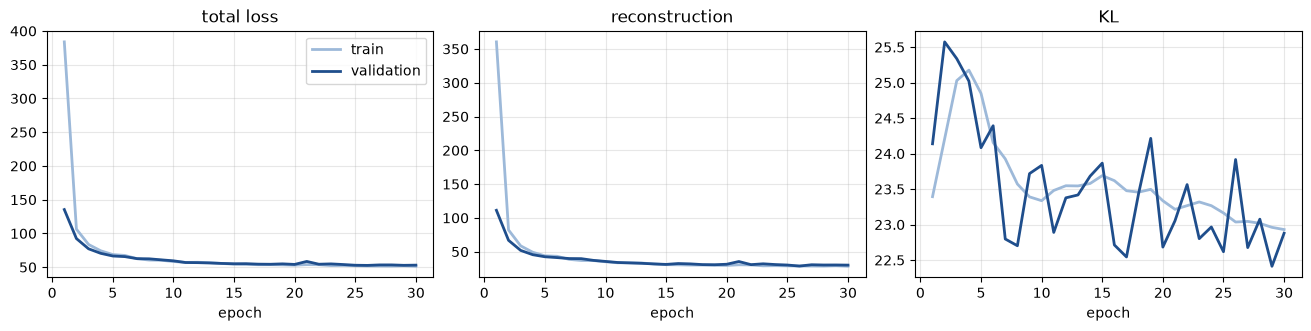

In [9]:
train_h, val_h = torch.stack(history["train"]), torch.stack(history["val"])
epochs = range(1, len(train_h) + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), constrained_layout=True)
for ax, i, title in zip(axes, range(3), ["total loss", "reconstruction", "KL"]):
    ax.plot(epochs, train_h[:, i], lw=2, color="#9db9d9", label="train")
    ax.plot(epochs, val_h[:, i], lw=2, color="#1f4e8c", label="validation")
    ax.set(title=title, xlabel="epoch"); ax.grid(alpha=0.3)
axes[0].legend();

## 7 · Reconstructions of test days (2020–2024)

The model never trained on these years. Top row: real day; bottom row: the map rebuilt from its code μ.
The first column is the windiest test day.

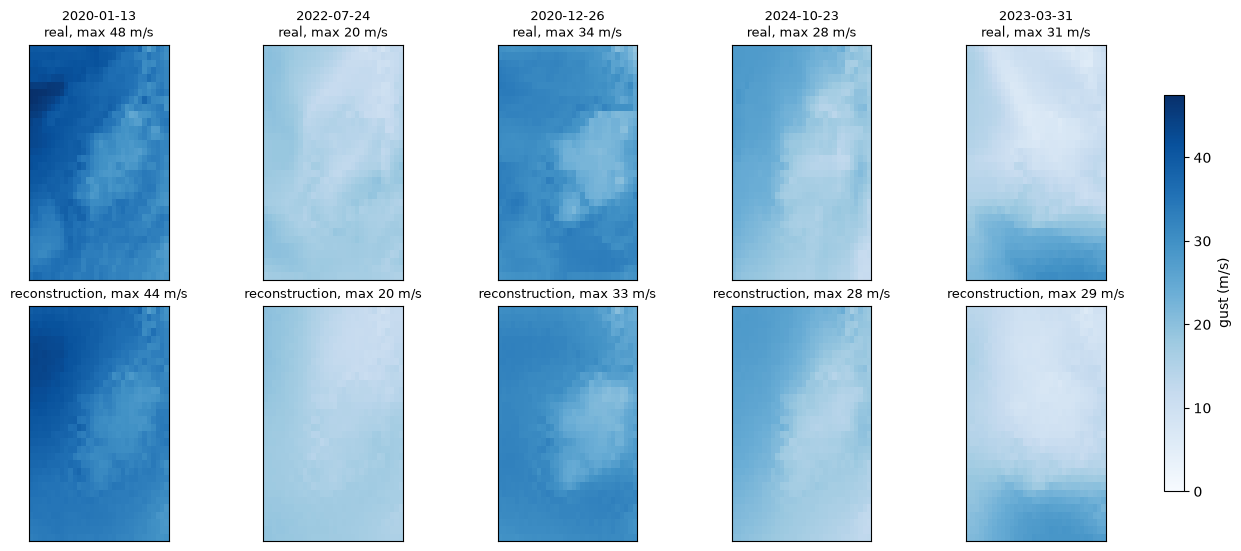

In [10]:
lon, lat = maps.longitude.values, maps.latitude.values
EXTENT = [lon.min() - 0.125, lon.max() + 0.125, lat.min() - 0.125, lat.max() + 0.125]
ASPECT = 1 / np.cos(np.deg2rad(53.5))     # cells are narrower E-W than N-S at Ireland's latitude

def show(ax, field, vmin, vmax, title=""):
    im = ax.imshow(field, origin="lower", extent=EXTENT, aspect=ASPECT, cmap="Blues", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    return im

@torch.no_grad()
def reconstruct(raw):
    x = normalise(raw).unsqueeze(1).to(device)
    mu, _ = model.encode(x)
    return denormalise(model.decode(mu).squeeze(1).cpu())

test_dates = maps.sel(time=slice("2020", "2024")).time.values
windiest = int(test_raw.amax(dim=(1, 2)).argmax())
idx = [windiest] + torch.randint(len(test_raw), (4,), generator=torch.Generator().manual_seed(SEED)).tolist()
real, recon = test_raw[idx], reconstruct(test_raw[idx])

fig, axes = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5.4), constrained_layout=True)
vmax = float(real.max())
for j, i in enumerate(idx):
    show(axes[0, j], real[j], 0, vmax, f"{str(test_dates[i])[:10]}\nreal, max {real[j].max():.0f} m/s")
    im = show(axes[1, j], recon[j], 0, vmax, f"reconstruction, max {recon[j].max():.0f} m/s")
fig.colorbar(im, ax=axes, label=f"{VARIABLE} (m/s)", shrink=0.8);

## 8 · New maps: sampling z ~ N(0, σ²)

Draw random codes and decode them. **σ = 1** matches the training cloud of codes; **σ > 1** reaches further
out, asking for more unusual (hopefully windier) maps; **σ < 1** gives more typical ones.

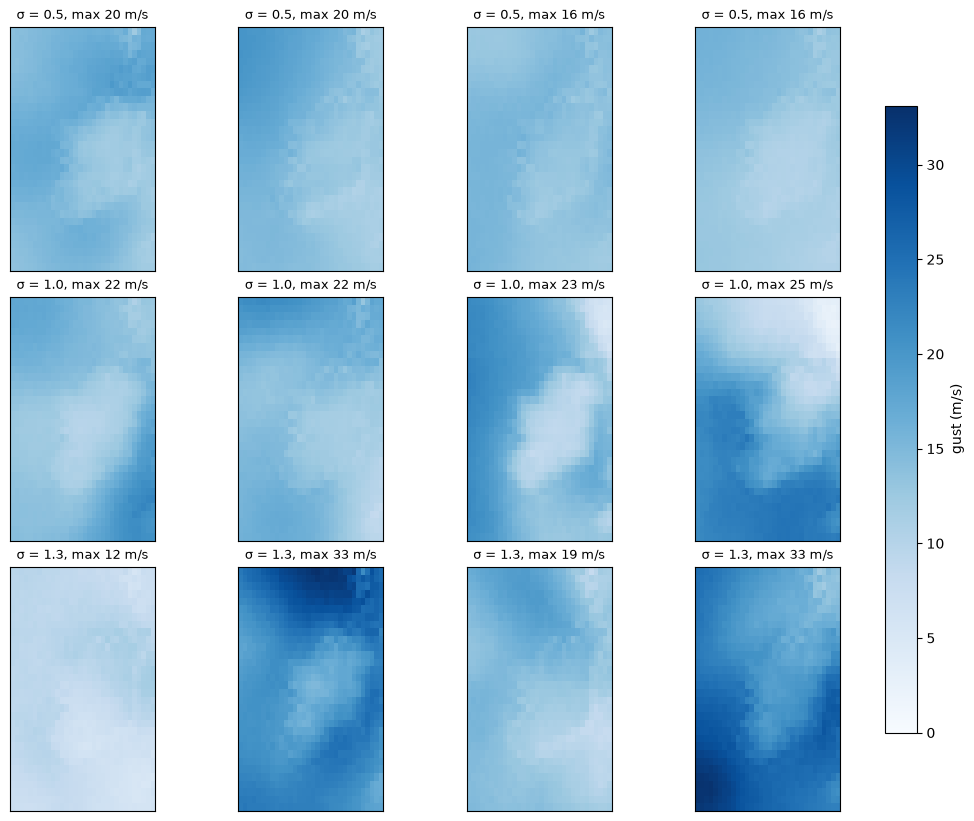

In [11]:
@torch.no_grad()
def sample(n, sigma):
    z = sigma * torch.randn(n, LATENT_DIM, device=device)
    return denormalise(model.decode(z).squeeze(1).cpu())

torch.manual_seed(SEED)
examples = {s: sample(4, s) for s in SIGMAS}
vmax = max(float(v.max()) for v in examples.values())
fig, axes = plt.subplots(len(SIGMAS), 4, figsize=(10.4, 2.7 * len(SIGMAS)), constrained_layout=True)
for r, s in enumerate(SIGMAS):
    for j in range(4):
        im = show(axes[r, j], examples[s][j], 0, vmax, f"σ = {s}, max {examples[s][j].max():.0f} m/s")
fig.colorbar(im, ax=axes, label=f"{VARIABLE} (m/s)", shrink=0.8);

## 9 · Are the samples as windy as real days?

For each map, take its **windiest pixel** (the domain maximum). Compare the spread of those values for the
real test days and for 2000 samples at each σ.

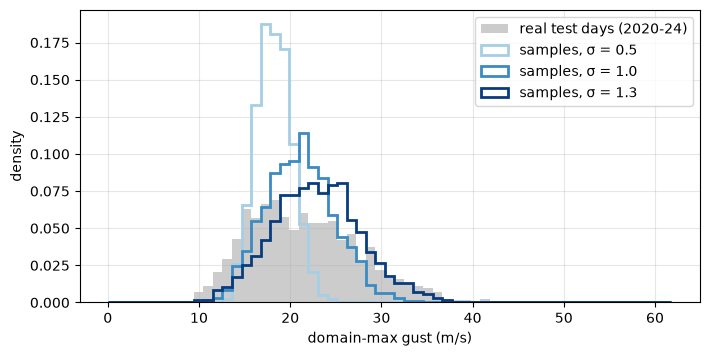

In [12]:
real_max = test_raw.amax(dim=(1, 2))
bins = np.linspace(0, float(real_max.max()) * 1.3, 60)
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(SIGMAS)))      # light -> dark as σ grows

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(real_max, bins=bins, density=True, color="0.8", label="real test days (2020-24)")
torch.manual_seed(SEED)
for s, colour in zip(SIGMAS, blues):
    ax.hist(sample(2000, s).amax(dim=(1, 2)), bins=bins, density=True, histtype="step", lw=2,
            color=colour, label=f"samples, σ = {s}")
ax.set(xlabel=f"domain-max {VARIABLE} (m/s)", ylabel="density"); ax.grid(alpha=0.3); ax.legend();

## 10 · Things to try

Change one setting at a time in Section 1, re-run everything, and note what changes:

1. **`BETA = 0`.** The loss becomes plain reconstruction. What happens to the KL curve, and to the σ = 1 samples?
2. **`BETA = 10`.** Do reconstructions get blurrier? Do the samples all start to look the same?
3. **`LATENT_DIM = 2` vs `64`.** How small can the code be before reconstructions lose the storm peaks?
4. **`EPOCHS = 3`.** How much worse is it? Is the validation loss still falling at the end of 30 epochs?
5. **`VARIABLE = "speed"`.** Is mean wind speed easier or harder to model than gusts?
6. **Section 9.** Which σ makes the samples' windiest days match the real windiest days? Does that σ also
   match the *typical* days, or does it shift everything?
7. **Break it on purpose.** Delete the KL term from `vae_loss` (keep only `recon`), retrain, and look at the
   σ = 1 samples. Why does sampling stop working?